**step1: importing requied libaries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df =pd.read_csv(r"C:\Users\Admin\Downloads\train.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


**Step3:Exploring the dataset**

In [3]:
df.shape

(614, 13)

In [4]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [6]:
df.dtypes

Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object

**step**
check for Duplicates**

In [7]:
df.duplicated().sum()

np.int64(0)

**dropping uplicate rows**

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.isna().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [10]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

**step**
**Separate out numerical columns & categorical columns**

In [11]:
numerical_cols= df. select_dtypes(include='number').columns
categorical_cols =df.select_dtypes(include ='object').columns
categorical_cols

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'Property_Area', 'Loan_Status'],
      dtype='str')

# step 4
**checking outlier for imputation of missing values**

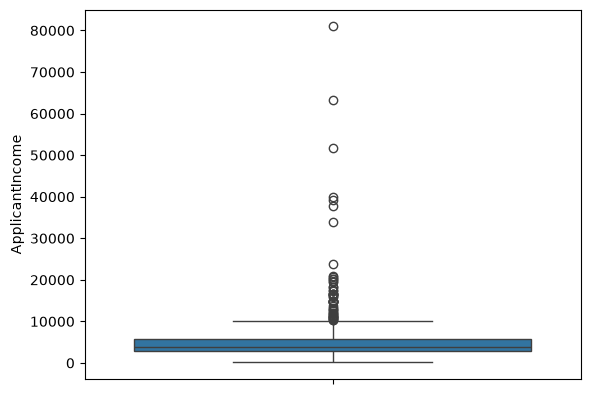

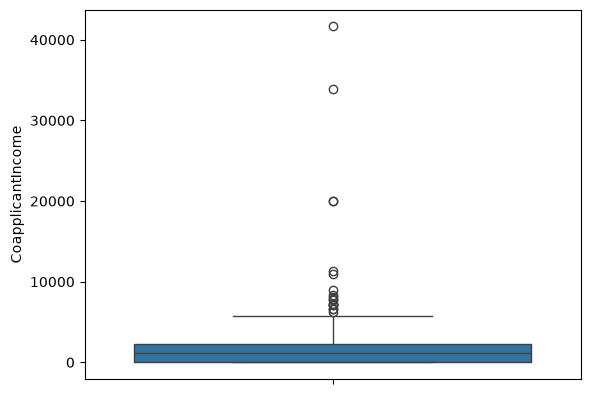

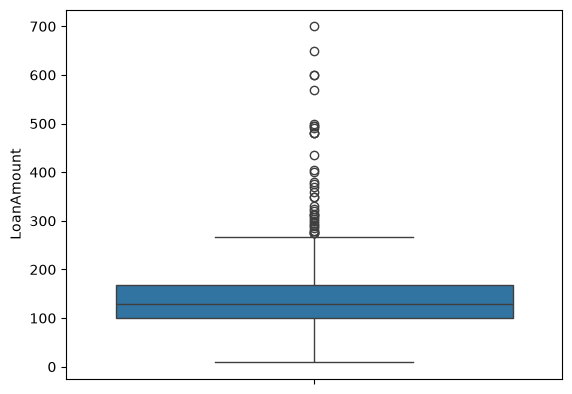

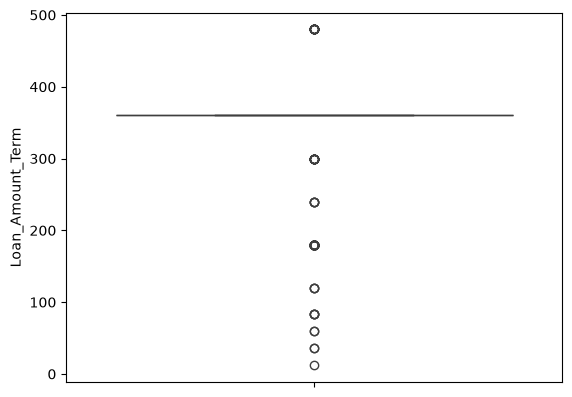

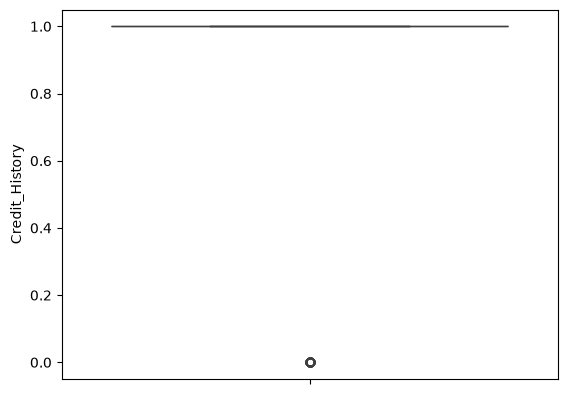

In [12]:
for i in numerical_cols:
    sns.boxplot(df[i])
    plt.show()

In [13]:
df["LoanAmount"] =df["LoanAmount"].fillna(df["LoanAmount"].median())
df["Loan_Amount_Term"] =df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].median())
df["Credit_History"] =df["Credit_History"].fillna(df["Credit_History"].median())

In [14]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

In [15]:
print(df["Gender"].mode())

0    Male
Name: Gender, dtype: str


In [16]:
df["Gender"].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [17]:
cat_cols =["Gender","Dependents","Self_Employed","Married"]
for i in cat_cols:
    df[i].fillna(df[i].mode()[0])   #mising values 

In [18]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

# 5 Handling outliers

#what is an outliers ?
#ans=> outliers is an observation that is far away from most of the other observation (exterme values)
#Example=> Age:22,25,27,29,31,30,28,150
#where 150 is an outlier

#first detect outliers usinf IQR method 
#Formula=> IQR(inter Quartile Range) formula=> =Q3-Q1
#Lower Bound Formula=> Q1-1.5*IQR
#Upper Bound Fromula=> Q3+1.5*IQR
#The data points that fall below upper bound & above upper are considered as ouliers


#romove the column  jo data lgnar nahi

In [19]:
df.drop(columns=['Loan_ID'],inplace=True)

In [20]:
categorical_cols =df.select_dtypes(include ='object').columns
categorical_cols

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Property_Area', 'Loan_Status'],
      dtype='str')

In [21]:
for i in numerical_cols:
    Q1 =df[i].quantile(0.25)
    Q3 =df[i].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1-1.5*IQR
    upper =Q3+1.5*IQR

    outliers =((df[i]<lower)|(df[i]>upper)).sum()

    print(i,"=",outliers)

ApplicantIncome = 50
CoapplicantIncome = 18
LoanAmount = 41
Loan_Amount_Term = 88
Credit_History = 89


In [22]:
for i in numerical_cols:
    Q1 =df[i].quantile(0.25)
    Q3 =df[i].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1-1.5*IQR
    upper =Q3+1.5*IQR
    df[i] =df[i].clip(lower,upper)

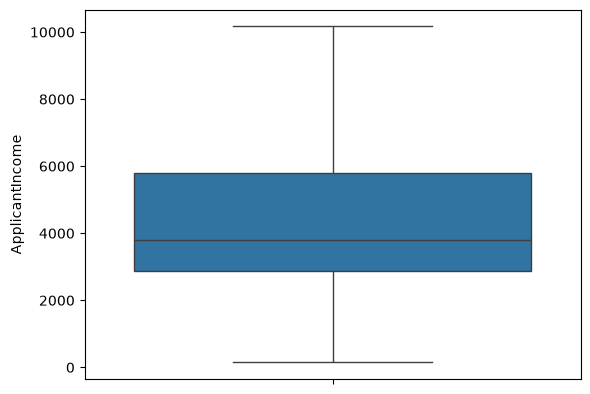

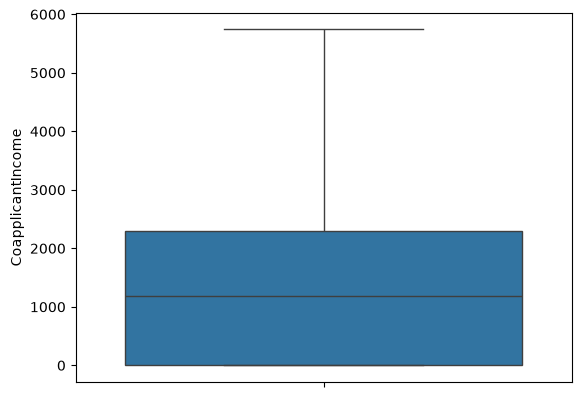

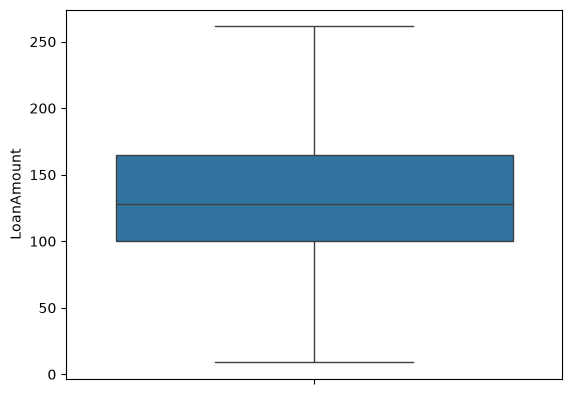

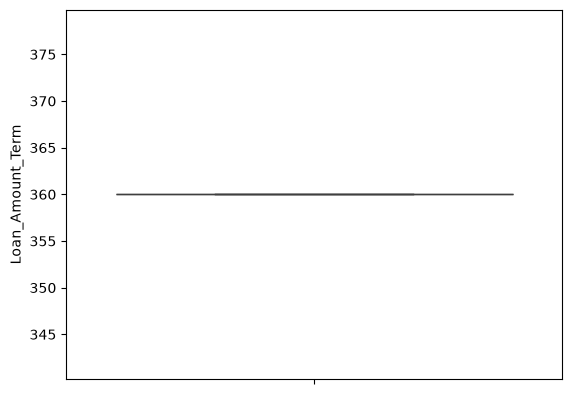

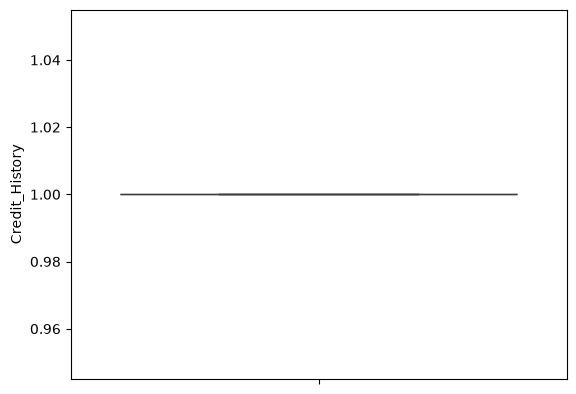

In [23]:
for i in numerical_cols:
    sns.boxplot(df[i])
    plt.show()

In [24]:
df.describe(include="number")

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,614.000000,614.0,614.0
mean,4617.111564,1419.702231,137.365635,360.0,1.0
std,2479.851729,1624.605892,55.779749,0.0,0.0
min,150.000000,0.000000,9.000000,360.0,1.0
25%,2877.500000,0.000000,100.250000,360.0,1.0
50%,3812.500000,1188.500000,128.000000,360.0,1.0
75%,5795.000000,2297.250000,164.750000,360.0,1.0
max,10171.250000,5743.125000,261.500000,360.0,1.0


# 6 Univeriate Analysis

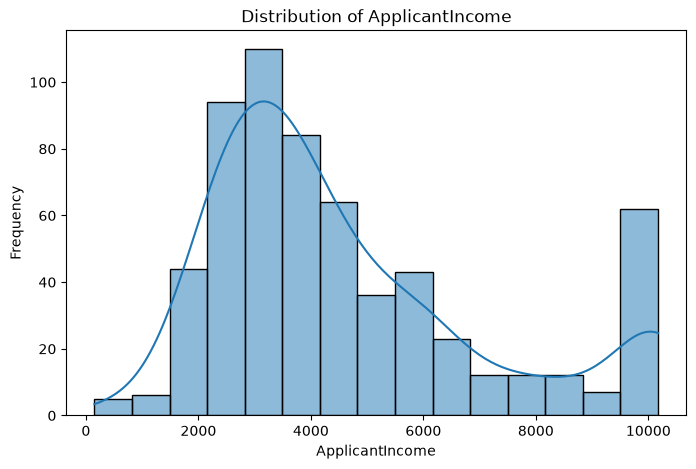

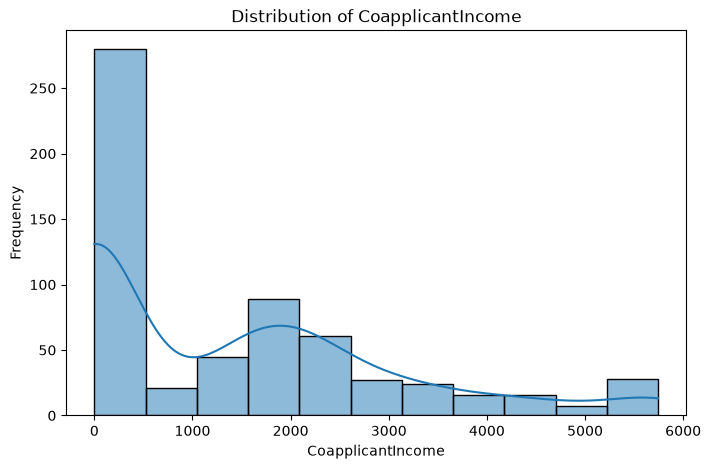

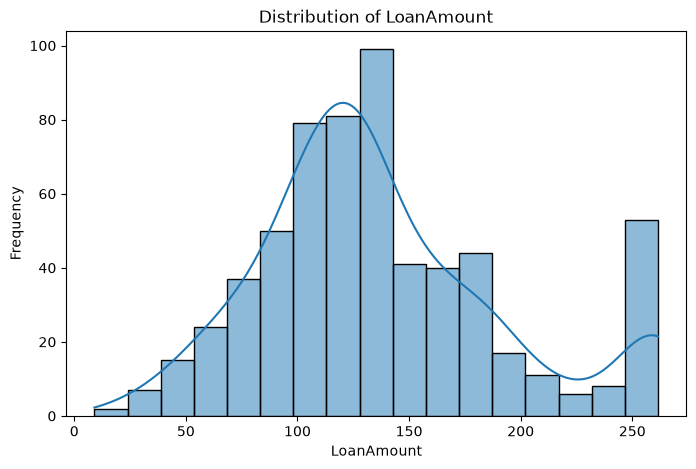

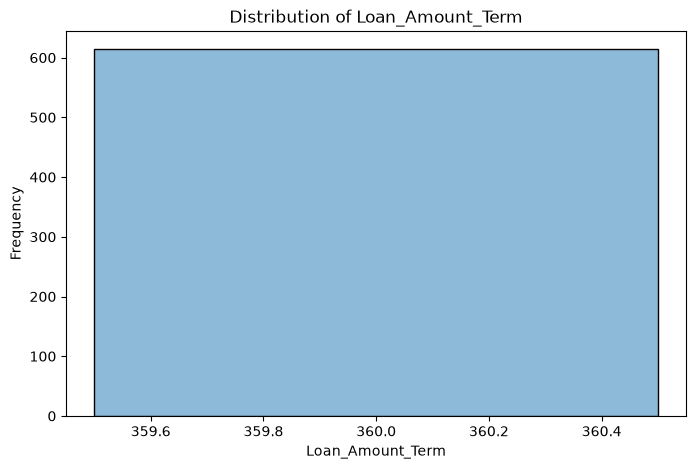

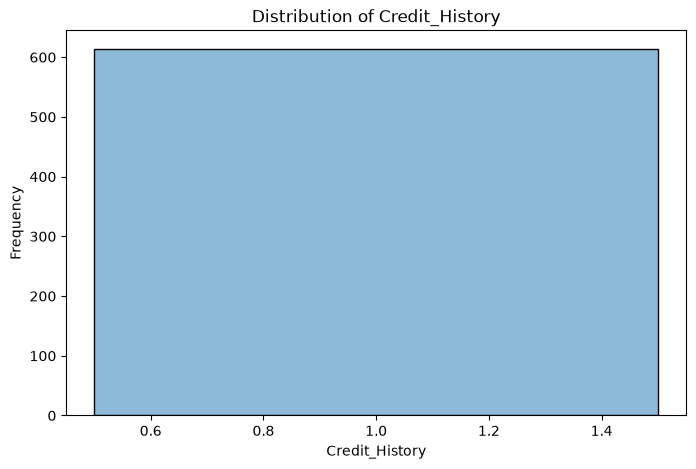

In [25]:
for i in numerical_cols:
    plt.figure(figsize = (8,5))
    sns.histplot(df[i],kde=True)
    plt.title(f"Distribution of {i}")
    plt.xlabel(i)
    plt.ylabel("Frequency")

    plt.show()


#Interpretation: ApplicantIncome is slighly positively skewed  distributed
#CoapplicatIncome is positively skwed distibuted 
#LoanAmount distribution is symmetric

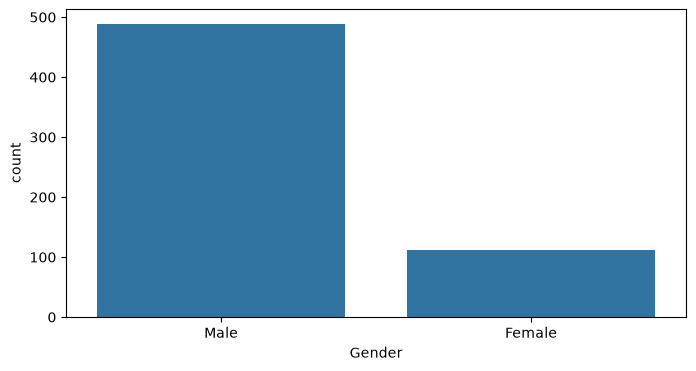

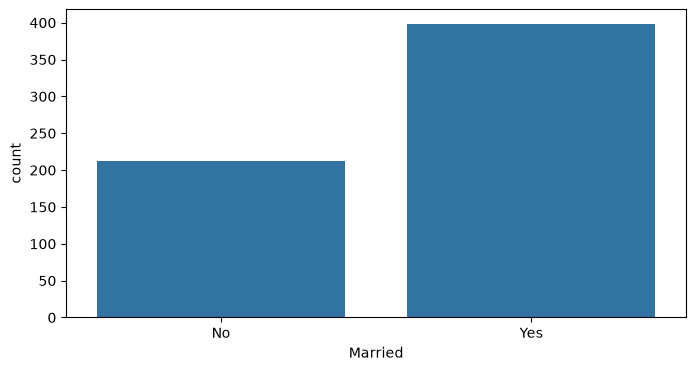

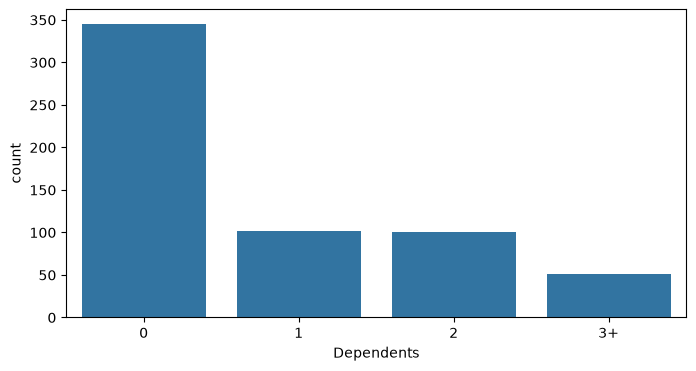

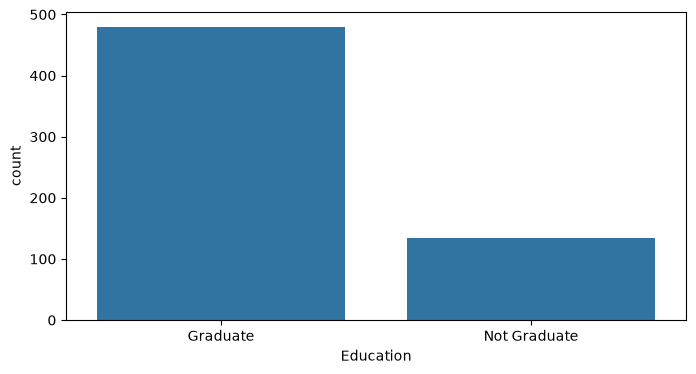

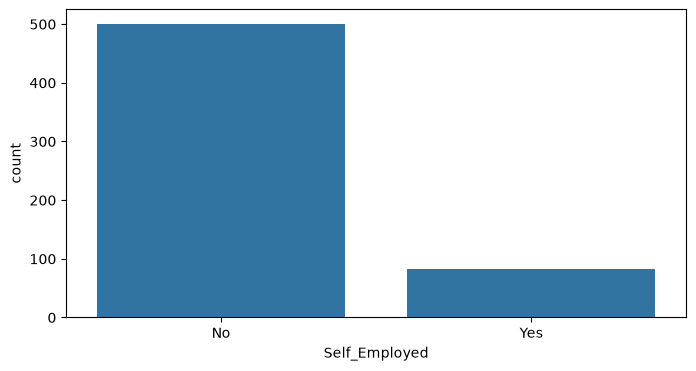

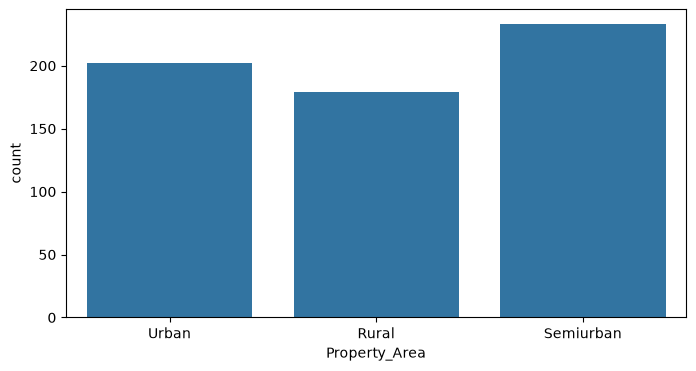

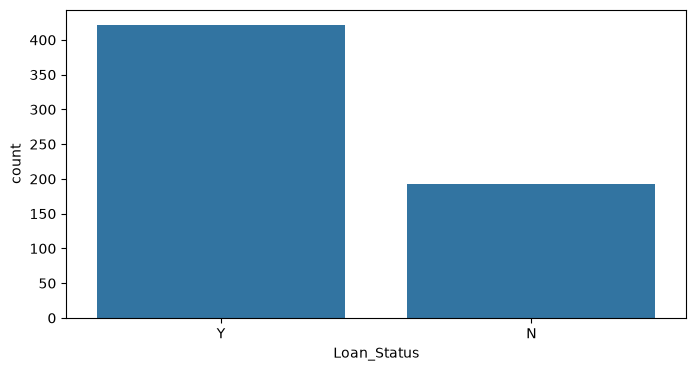

In [26]:
for i in categorical_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df,x=i)
    plt.show()

#Interpretation: Male candidates apply to Loan more than feamle condidates
#Married people are more as compared to unmaried people in our data
#Married men's applying more to loan 
#Graduate count is more in our data
#self employeed count is less in out data means self empolyed people are not  are likely
#applying for loans

**Multivariate Analyis**

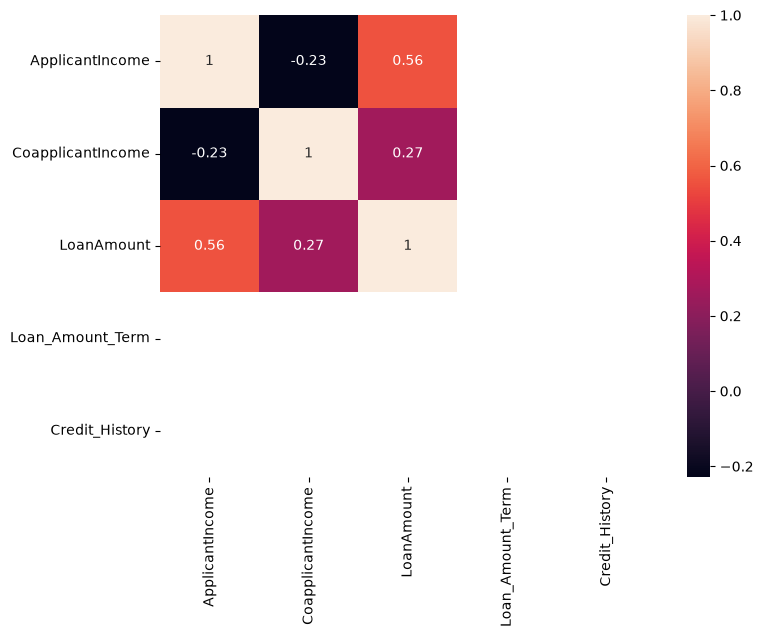

In [27]:
#heatmap
plt.figure(figsize=(8,6))
sns.heatmap(
    df[numerical_cols].corr(),
        annot=True
)
plt.show()

#There is considerable correlation between income & Loan amount

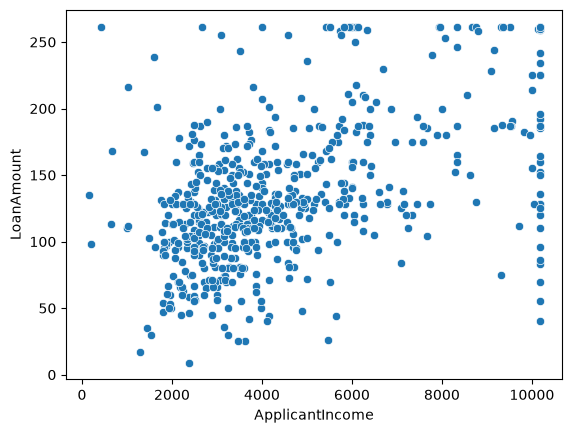

In [28]:
sns.scatterplot(data=df,x="ApplicantIncome",y="LoanAmount")
plt.show()

**Group By Analysis**

In [29]:
#1) Average Applicant Income By Gender
print(df.groupby('Gender')["ApplicantIncome"].mean())

#2) Average Applicant Income By Education
print(df.groupby('Education')["LoanAmount"].mean())
#3)Total Applicant Income By Property Area
print(df.groupby('Property_Area')["ApplicantIncome"].sum())

#3Average Applicant Income By Education
print(df.groupby('Property_Area')["LoanAmount"].mean())

      

Gender
Female    4275.921875
Male      4669.553170
Name: ApplicantIncome, dtype: float64
Education
Graduate        142.554167
Not Graduate    118.779851
Name: LoanAmount, dtype: float64
Property_Area
Rural         849840.75
Semiurban    1063341.50
Urban         921724.25
Name: ApplicantIncome, dtype: float64
Property_Area
Rural        142.659218
Semiurban    137.903433
Urban        132.054455
Name: LoanAmount, dtype: float64


#Interpretation From  this we conslude that male candidates earning more than feamle condidates 
#but here male count is also more than female count
#More Loan taken bby Graduates than Non graduates
#People staying in Semiurbon area more but
#people staying  in Rural area taking more Loans and earning Less

In [30]:
#Loan Approval count by Education
print(df.groupby("Education")["Loan_Status"].value_counts())
#Average Income By Loan Status 
print(df.groupby('Loan_Status')["ApplicantIncome"].mean())

Education     Loan_Status
Graduate      Y              340
              N              140
Not Graduate  Y               82
              N               52
Name: count, dtype: int64
Loan_Status
N    4618.735677
Y    4616.372630
Name: ApplicantIncome, dtype: float64


Iterpretation=> Graduates:340 loan were approved & 140 were rejected
Not graduates :82 loan were approved &52 were rejected.
So,graducates have a higher loan approval count than non-graducates.
However, number of applicants in each group is differnt, so countsalone alone din't tell us the 
approval rate 
For the second analysis:
Avergae income of applicats whose loan was rejected(N)=4618.74
Average income of applicants whose loan was approved (y)=4616.37.
The diiffernce is only about 2.36 which is extremely small
Overall conslusion:
Education apppers to have same assocition with loan approval, with graducates having more loan 
approvals. However Applicat income does not apper to have a meaninful difference between 
approvals & rejected loans in this datatset THerefore income alone does not seem to strongly
infulence loan approval.

In [31]:
df.to_csv(r"C:\Users\Admin\OneDrive\Desktop\loanApproval.csv",index=False)